In [1]:
# Importaciones básicas
import sys
sys.path.insert(0, '../src')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Configurar visualizaciones
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print(f"⏰ Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

⏰ Notebook iniciado: 2026-02-03 13:48:22


In [ ]:
# Crear sesión Spark con configuración optimizada para Jupyter
spark = crear_sesion_spark(
    app_name="TFM_Experimento_01",
    master="local[*]",
    driver_memory="4g",
    executor_memory="4g",
    ui_port=4040,
    verbose=False  # Cambiar a True para ver más logs
)

# Mostrar información de Spark
mostrar_info_spark(spark, ui_port=4040)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/02/03 13:48:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_Experimento_01
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 4
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores



----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 58457)
Traceback (most recent call last):
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/socketserver.py", line 747, in __init__
    self.handle()
  File "/Users/franmateos/Documents/Formacion/Master 

In [3]:
# Test 1: Crear RDD simple
print("TEST 1: RDD básico")
rdd = spark.sparkContext.parallelize(range(1000000))
resultado = rdd.map(lambda x: x**2).sum()
print(f"✓ Suma de cuadrados (0 a 999999): {resultado:,}")

# Ahora puedes ver en http://localhost:4040 cómo se ejecutó este job

TEST 1: RDD básico
✓ Suma de cuadrados (0 a 999999): 333,332,833,333,500,000


In [4]:
# Test 2: DataFrame Spark
print("\nTEST 2: DataFrame Spark")
datos = [
    ("Alice", 25, "Engineering"),
    ("Bob", 30, "Finance"),
    ("Charlie", 35, "Engineering"),
    ("David", 28, "HR"),
]

df_spark = spark.createDataFrame(datos, ["Nombre", "Edad", "Departamento"])
print(f"Schema del DataFrame:")
df_spark.printSchema()
print(f"\nPrimeras filas:")
df_spark.show()

# Puedes ver en http://localhost:4040 > Storage cómo se cachea


TEST 2: DataFrame Spark
Schema del DataFrame:
root
 |-- Nombre: string (nullable = true)
 |-- Edad: long (nullable = true)
 |-- Departamento: string (nullable = true)


Primeras filas:
+-------+----+------------+
| Nombre|Edad|Departamento|
+-------+----+------------+
|  Alice|  25| Engineering|
|    Bob|  30|     Finance|
|Charlie|  35| Engineering|
|  David|  28|          HR|
+-------+----+------------+



In [5]:
# Test 3: Spark SQL
print("\nTEST 3: Spark SQL")
df_spark.createOrReplaceTempView("empleados")
resultado_sql = spark.sql("""
    SELECT Departamento, COUNT(*) as cantidad, AVG(Edad) as edad_promedio
    FROM empleados
    GROUP BY Departamento
    ORDER BY cantidad DESC
""")
resultado_sql.show()


TEST 3: Spark SQL
+------------+--------+-------------+
|Departamento|cantidad|edad_promedio|
+------------+--------+-------------+
| Engineering|       2|         30.0|
|     Finance|       1|         30.0|
|          HR|       1|         28.0|
+------------+--------+-------------+




TEST 4: Conversión a Pandas y visualización


/Users/franmateos/Documents/Formacion/Master MDS/TFM/Desarrollo/AFSGAW/spark_env/lib/python3.9/site-packages/pyspark/sql/pandas/conversion.py:111: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  PyArrow >= 4.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


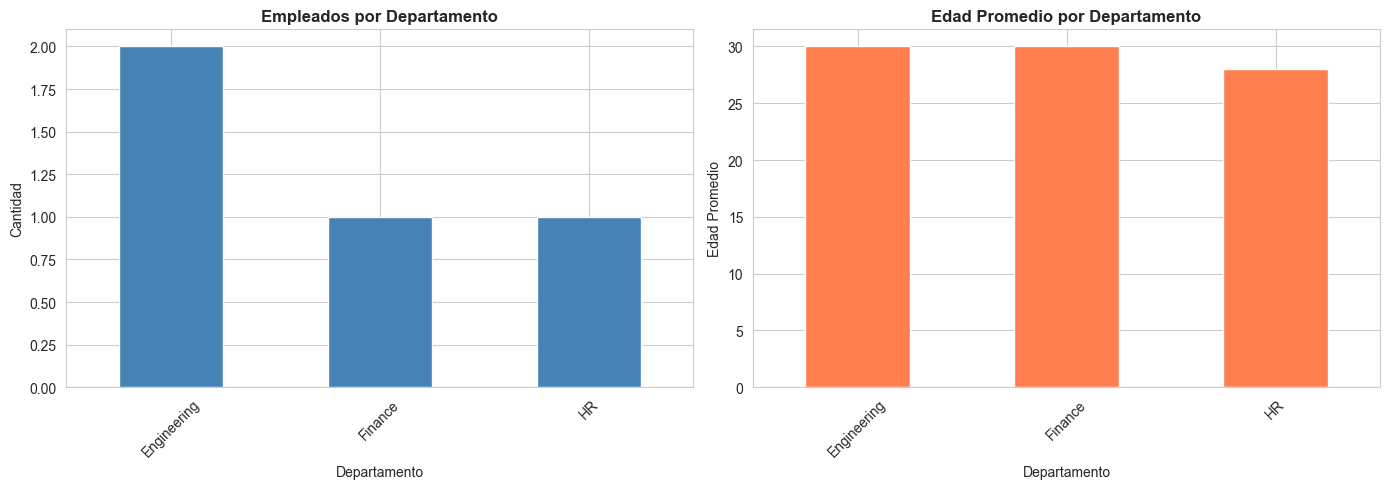

26/02/03 15:30:20 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 1013044 ms exceeds timeout 120000 ms
26/02/03 15:30:20 WARN SparkContext: Killing executors is not supported by current scheduler.
26/02/03 15:47:47 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:124)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$

In [6]:
# Test 4: Visualización con datos de Spark
print("\nTEST 4: Conversión a Pandas y visualización")

# Convertir a Pandas para visualizar
df_pandas = resultado_sql.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Cantidad por departamento
df_pandas.plot(x='Departamento', y='cantidad', kind='bar', ax=axes[0], legend=False, color='steelblue')
axes[0].set_title('Empleados por Departamento', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Cantidad')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2: Edad promedio por departamento
df_pandas.plot(x='Departamento', y='edad_promedio', kind='bar', ax=axes[1], legend=False, color='coral')
axes[1].set_title('Edad Promedio por Departamento', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Edad Promedio')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()